In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
%reload_ext autoreload
%autoreload 2

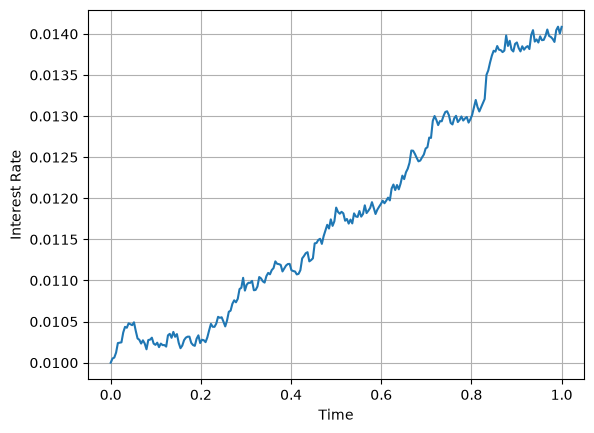

In [3]:
from simulation import CIR



model1 = CIR(kappa=0.5, theta=0.02, sigma=0.01, r0=0.01, T=1, N=252)

model1.simulate_path()
model1.plot()

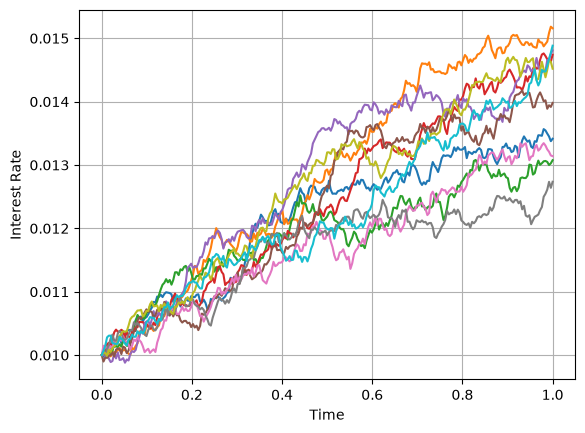

In [5]:
from simulation import CIR



model1 = CIR(kappa=0.5, theta=0.02, sigma=0.01, r0=0.01, T=1, N=252)

model1.simulate_multiple_paths(M=10)
model1.plot_multiple_paths()

In [18]:
model = CIR(kappa=0.5, theta=0.02, sigma=0.01, r0=0.01, T=1, N=252)

res = model.get_monte_carlo_estimate(M=10, confidence=0.95)

In [19]:
res.keys()

dict_keys(['times', 'mean', 'median', 'variance', 'ci_lower', 'ci_upper', 'q_lower', 'q_upper'])

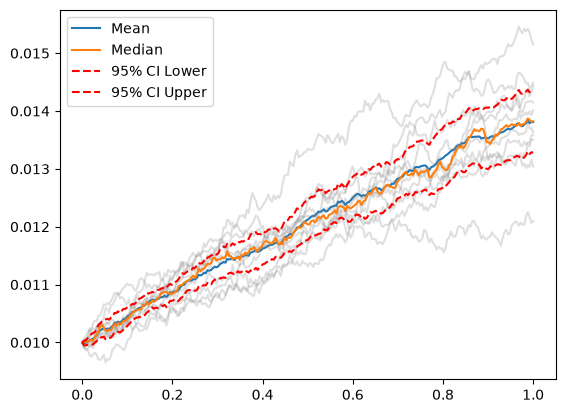

In [25]:
plt.plot(res["times"], res["mean"], label="Mean")
for plot in model.paths:
    plt.plot(res["times"], plot, color='gray', alpha=0.25)
plt.plot(res["times"], res["median"], label="Median")
plt.plot(res['times'], res['ci_lower'], label=f"{int(0.95*100)}% CI Lower", linestyle='--', color='red')
plt.plot(res['times'], res['ci_upper'], label=f"{int(0.95*100)}% CI Upper", linestyle='--', color='red')
plt.legend()

In [27]:
!pip install openpyxl

     -------------------------------------- 250.9/250.9 kB 1.7 MB/s eta 0:00:00



[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
history = pd.read_excel("RC_F01_01_2014_T09_12_2021.xlsx")

c:\Users\nikita\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [47]:
history.shape

(1957, 4)

In [32]:
history

,nominal,data,curs,cdx
0,1,2021-12-09,73.8453,Доллар США
1,1,2021-12-08,74.1399,Доллар США
2,1,2021-12-07,73.6694,Доллар США
3,1,2021-12-04,73.7426,Доллар США
4,1,2021-12-03,74.0637,Доллар США
...,...,...,...,...
1952,1,2014-01-15,33.2386,Доллар США
1953,1,2014-01-14,33.1204,Доллар США
1954,1,2014-01-11,33.2062,Доллар США
1955,1,2014-01-10,33.1547,Доллар США


In [40]:
lower_bound = 73.84 - 0.5
upper_bound = 73.84 + 0.5
start_date = pd.to_datetime("2021-12-10")
end_date = pd.to_datetime("2021-12-15")
nominal = 1000000


In [ ]:
model = CIR(kappa=0.5, theta=0.02, sigma=0.01, r0=history['curs'][0], T=10, N=100)

In [46]:
model.simulate_multiple_paths(M=20)

[array([73.8453    , 70.17029955, 66.61692716, 63.27325408, 60.09297111,
        57.07828952, 54.20793986, 51.52548591, 48.94080754, 46.48473254,
        44.16024827, 41.95308344, 39.87274753, 37.86871276, 35.99013789,
        34.18269608, 32.47649696, 30.84291874, 29.29942367, 27.84851681,
        26.43708273, 25.1003935 , 23.86224484, 22.66186881, 21.54875947,
        20.47474335, 19.45570834, 18.46093526, 17.54631342, 16.69190209,
        15.87321555, 15.07725521, 14.32802726, 13.60744638, 12.92513611,
        12.30374626, 11.69362229, 11.0965184 , 10.54488326, 10.03602315,
         9.53170684,  9.04609952,  8.60258655,  8.18203468,  7.77637968,
         7.39702979,  7.03345294,  6.68295736,  6.35522268,  6.03818311,
         5.7254717 ,  5.43462553,  5.16130095,  4.90069081,  4.65533227,
         4.42462377,  4.20496183,  3.99626236,  3.79192094,  3.61059124,
         3.43264446,  3.26598324,  3.09853911,  2.95045001,  2.80814771,
         2.66676206,  2.53422176,  2.40337642,  2.2

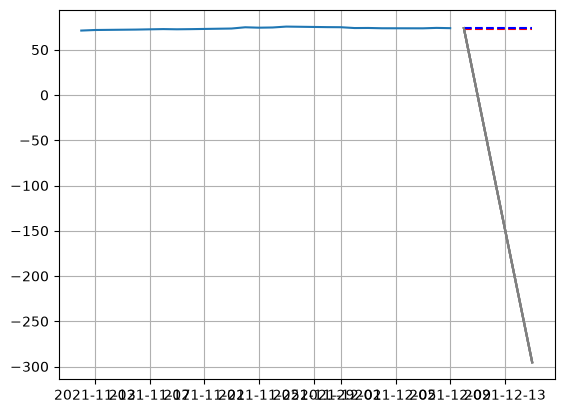

In [44]:
plt.plot(history['data'][:20], history['curs'][:20])
plt.plot([start_date, end_date], [lower_bound, lower_bound], color='red', linestyle='--', label='Lower Bound')
plt.plot([start_date, end_date], [upper_bound, upper_bound], color='blue', linestyle='--', label='Upper Bound')

for path in model.paths:
    plt.plot([start_date, end_date], [path[0], path[-1]], color='gray', alpha=0.25)
plt.plot()
plt.grid()